
# How navigable is the Congo today? — student notebook

**Download the SWOT water levels of every river reach in the Congo basin, find the lowest and highest level each reach
has had since July 2023, and map where the rivers stand today between those two.**

**Start here:** menu **Run ▸ Run all** (Colab: **Runtime ▸ Run all**), then read from the top.

The first run downloads the SWOT record of all 4,444 river reaches of the basin from NASA's Hydrocron service — about
10 minutes, no account needed. Later runs re-use the saved files and only download again what is more than three days
old. Without internet the notebook uses the copy shipped with the `virtualgauge` package (downloaded 16 November 2026).
About 60 minutes.

✏️ a line you can change — 🧪 try it — 💬 questions to discuss

**Contents** — 1 From water level to navigability · 2 Every SWOT reach in the Congo basin · 3 The lowest and highest recorded levels · 4 The navigability of the Congo today · 5 Along the river and at the ports · 6 Through time · 7 Change the settings · 8 Export and summary

[![Open in Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/simreaney/virtualgauge/blob/main/Congo_Navigability_Student.ipynb)


In [1]:
#@title Setup { display-mode: "form" }
import glob, importlib, importlib.util, subprocess, sys
from pathlib import Path


def _needs_install():
    spec = importlib.util.find_spec("virtualgauge")            # finds the package without importing it
    return spec is None or not (Path(spec.origin).parent / "navigation.py").exists()


if _needs_install():                      # install once (Colab / new computer)
    REPO_URL = "https://github.com/simreaney/virtualgauge"
    here = Path.cwd()
    local = [str(here)] if (here / "src" / "virtualgauge" / "navigation.py").exists() else []   # this repository
    wheel = sorted(glob.glob("virtualgauge-*.whl"))
    for source in local + wheel[-1:] + [f"git+{REPO_URL}"]:
        print(f"Installing: {source}")
        pip = subprocess.run([sys.executable, "-m", "pip", "install", "-q", "--upgrade", source],
                             capture_output=True, text=True)
        if pip.returncode == 0:
            break
    importlib.invalidate_caches()
    if pip.returncode != 0:
        print((pip.stderr or pip.stdout)[-1500:])
        raise RuntimeError("Could not install virtualgauge. Upload the virtualgauge-*.whl file (Files panel) "
                           "and run this cell again.")
import virtualgauge as vg
vg.set_language("en")
print(f"virtualgauge {vg.__version__} — ready")

Installing: /Users/simreaney/Documents/GitHub/virtualgauge
virtualgauge 0.2.0 — ready


## Part 1 — From water level to navigability

The Congo and its tributaries carry boats, barges and ferries over thousands of kilometres: from Kinshasa up to
Kisangani (about 1,700 km), up the Kasai to Ilebo, up the Ubangi to Bangui, up the Sangha to Ouesso, and on the Lualaba
above Kisangani. Below Kinshasa the Livingstone Falls block the way to the sea port of Matadi; just above Kisangani the
Boyoma Falls block the way upstream.

What a boat needs is **depth**, above all over the shallowest places — sand bars and rocky sills. When the river is
low, barges must carry less or stop. Nobody measures depth over the whole basin, but the satellite **SWOT** (NASA and
CNES, since July 2023) measures the **height of the water surface** on every river reach wider than about 100 m, two to
four times every 21 days. On a given reach, a higher water surface means more water over the shallows.

So we compare each reach **with itself**: where is its water level today, between the lowest and the highest level
SWOT has recorded there?

> **navigability index = 100 × (latest level − lowest level) ÷ (highest level − lowest level)**

| index | | |
|---|---|---|
| 0–20 | very poor | the river is as low as SWOT has seen it here |
| 20–40 | poor | |
| 40–60 | fair | |
| 60–80 | good | |
| 80–100 | very good | the river is as high as SWOT has seen it here |

💬 **What do you notice?**

- Is high water always better for boats? Think of the current, floating vegetation, flooded ports and bridges.
- Why compare each reach with its own record, instead of comparing the water level of different rivers?
- The record starts in July 2023. In December 2023 the Congo at Kinshasa rose to its highest level since 1961. What does that do to the ‘highest level’ of the reaches near Kinshasa — and to their index in later years?
- The index says nothing about rapids or waterfalls. Which parts of the Congo are never navigable, whatever the index?

## Part 2 — Every SWOT reach in the Congo basin

SWOT reports one water level per **reach** — a stretch of river about 10 km long, from the SWORD river database. The
Congo basin has 4,444 of them (narrow streams to the 4 km wide main river), and each has its own record on Hydrocron.

### 2.1 Download

This one line downloads the SWOT record of every reach, eight at a time, and cleans it. The first time it takes about
10 minutes; a progress line shows how far it has got. If it stops (or you stop it), run the cell again: it continues
where it stopped. The files are saved in the folder `cache/survey_reaches/`, one per reach.

In [2]:
congo = vg.river_survey("congo")   # ✏️ update_days=3: download again what is older than this
congo

Downloaded 4 444 of 4 444 reaches (4 396 with SWOT levels, 48 without, 0 failed) — about 0 min left   


River survey — Congo basin
4 444 SWOT river reaches; 4 305 of them have SWOT levels — 392 221 good levels in all, from 1 July 2023 to 12 November 2026.
Downloaded from Hydrocron on 16 November 2026: 4 444 reaches now, 0 saved in the last days, 0 failed.
Next: .coverage() .cleaning() .ranges() .navigability() .map() .profile() .reach(id) .ports() .history() .export()

### 2.2 Which reaches does SWOT measure?

The colour shows how many good SWOT levels each reach has. Pale grey: no good level at all.

,reach,reaches
0,index possible,3629
1,too noisy,470
2,too few good levels,204
3,never measured,91
4,no SWOT data,48
5,range too small,2

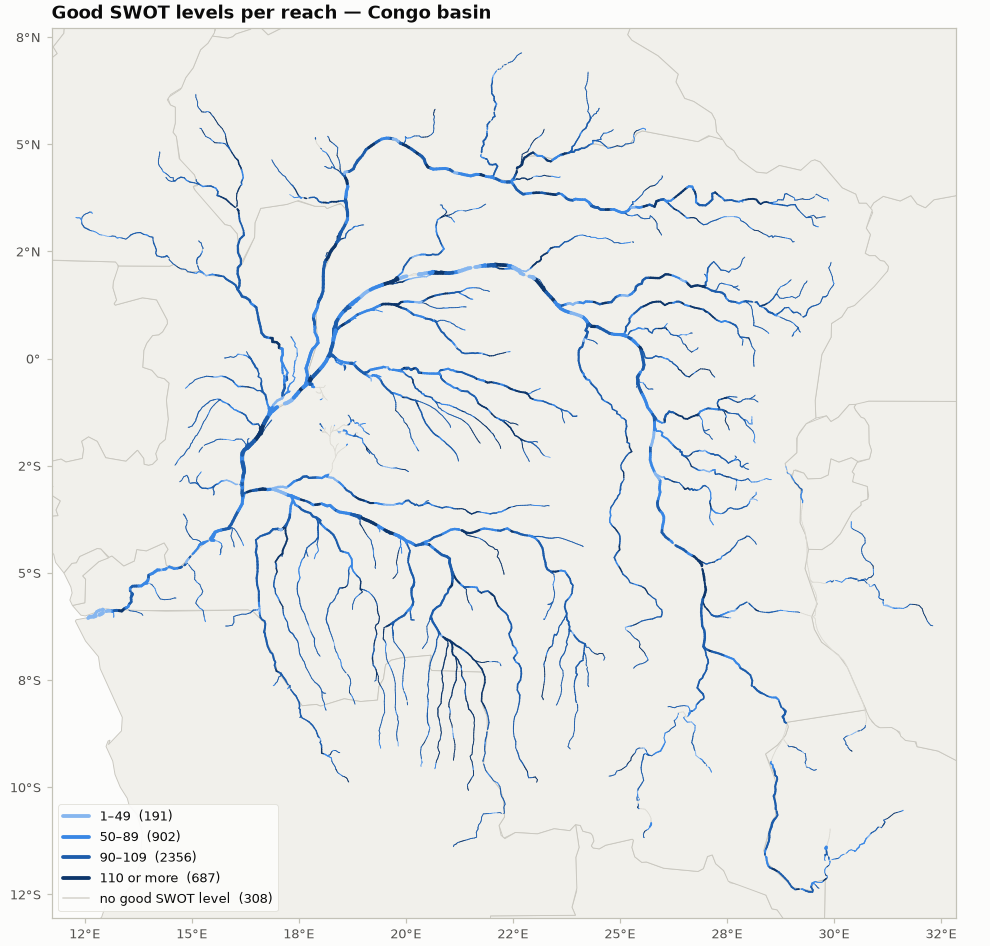

In [3]:
congo.coverage()

💬 **What do you notice?**

- Which rivers have the most levels? Which have none? Is it a matter of width?
- Find the stretch of the Congo between Mbandaka and Bumba (around 19–22° E, 1–2° N) with few levels. The river is very wide there, with many islands and channels. Why might that be hard for SWOT?

### 2.3 Which levels can we trust?

As in the virtual gauge notebook, every level that is removed has a written reason: a poor quality flag, a level far
from all the other levels of its reach, or a **spike** — a level that jumps away from the levels just before and after
it. Rivers rise and fall slowly; a level 2 m away from levels measured a few days earlier is an error, not a flood.

In [4]:
congo.cleaning()

,reason,levels,%
0,kept,392221,82.3
1,quality flag reach_q > 1,73962,15.5
2,spike (far from the levels just before and after it),6940,1.5
3,far from the reach's other levels,3385,0.7
4,duplicate,304,0.1


💬 **What do you notice?**

- What share of the SWOT levels is kept?
- Why is it important to remove spikes *before* we look for the lowest and the highest level?

## Part 3 — The lowest and highest recorded levels

For each reach: the lowest and the highest good level since July 2023, and the **range** between them. A reach gets a
range only if its record can be trusted: enough good levels, spread over at least a year (so that low and high water
are both in it), and levels that do not jump around from one pass to the next (*too noisy*).

,reaches,median_range_m,largest_range_m
river_name,,,
Ngoko River,10,8.12,9.75
Lua,6,6.94,16.6
Ubangi,23,6.8,8.64
Ubangi River,58,6.8,9.97
Ouara,8,6.65,7.64
Mbari,12,6.55,7.79
Chinko,26,6.43,8.31
Lokolo,9,6.19,8.87
Likouala-aux-Herbes,20,6.03,8.4

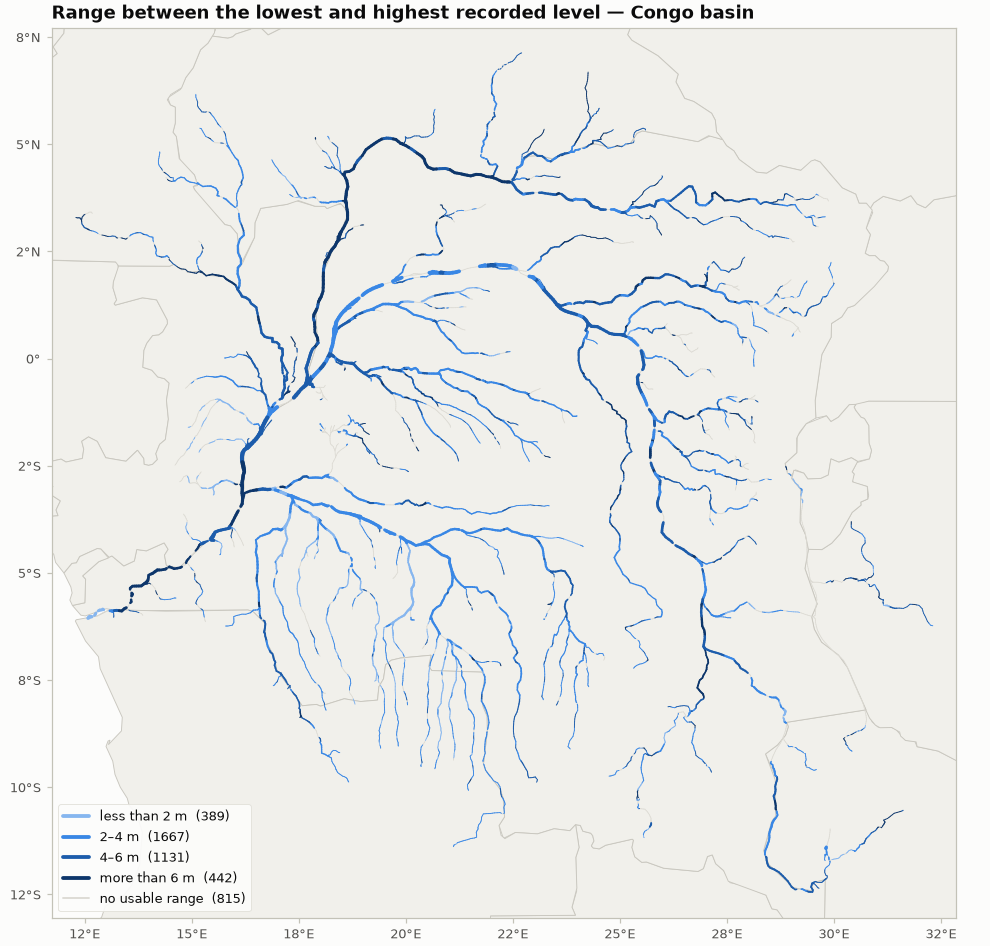

In [5]:
congo.ranges()

💬 **What do you notice?**

- Which rivers have the largest range? Which the smallest? Why might the range of a river change along its course?
- Most reaches with no range are narrow. Why is a narrow river harder for SWOT?

### 3.1 One reach: the Congo at Mbandaka

Every good level (blue), the levels removed by the cleaning (grey crosses), the lowest and highest recorded level
(dashed), and the latest level, coloured by its index.

Reach 13273000011 — Congo
Congo at 0.138, 18.238; about 3 405 m wide; SWORD type: river.
99 good SWOT levels (of 110), from 29 July 2023 to 25 October 2026.
Lowest 303.24 m (28 July 2025), highest 307.27 m (7 January 2024): a range of 4.03 m. Levels a few days apart typically differ by 0.13 m.
Latest level 304.82 m on 25 October 2026: index 39 — 20–40 poor.
For ICESat-2 levels and a discharge rating: vg.build_station("13273000011")
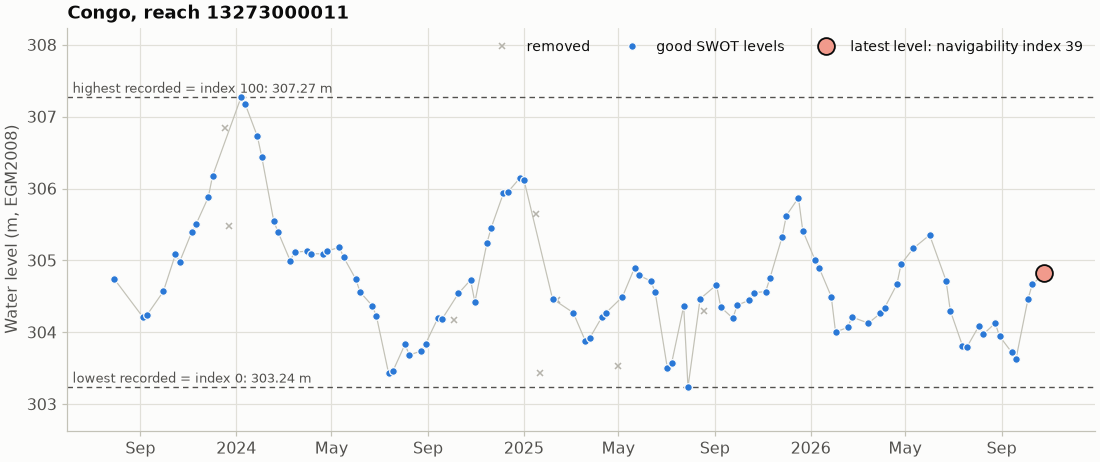

In [6]:
congo.reach("13273000011")   # ✏️ any reach ID: click a river on the map in Part 4

💬 **What do you notice?**

- When was the highest level recorded, and the lowest? Do they match what you know of the Congo's seasons?
- Each SWOT level has an error of about 10 cm. How much does that move the index of this reach?

### 3.2 🧪 A harder reach: the Congo at Bumba

Reach 13275700241 — Congo
Congo at 2.158, 22.452; about 3 482 m wide; SWORD type: river.
61 good SWOT levels (of 120), from 2 July 2023 to 28 October 2026.
Lowest 347.26 m (17 September 2026), highest 349.51 m (29 November 2025): a range of 2.25 m. Levels a few days apart typically differ by 0.11 m.
Latest level 348.48 m on 28 October 2026: index 54 — 40–60 fair.
For ICESat-2 levels and a discharge rating: vg.build_station("13275700241")
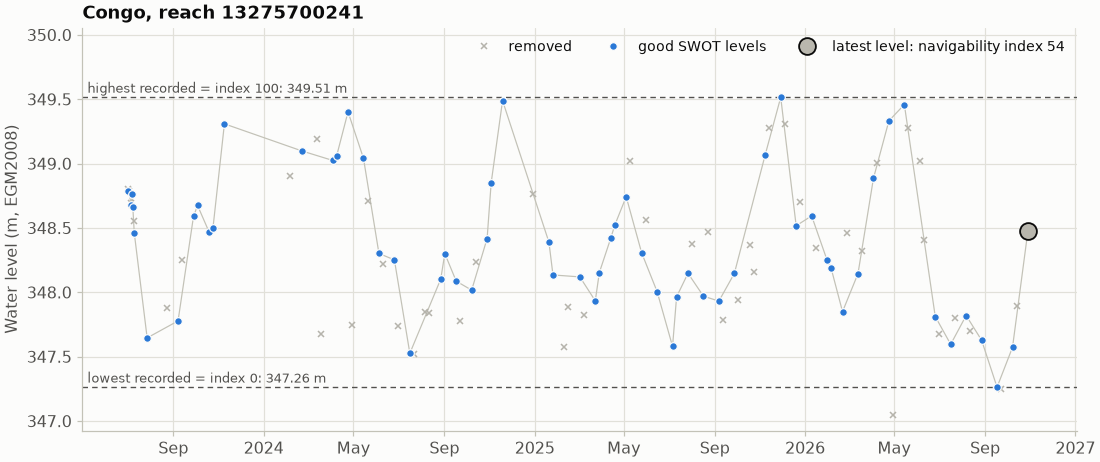

In [7]:
congo.reach("13275700241")

💬 **What do you notice?**

- Compare this record with Mbandaka. Which do you trust more, and why?
- The lowest and highest levels are each one single measurement. What happens to the index of every later date if one of them is wrong?

## Part 4 — The navigability of the Congo today

Each reach gets an index from its **latest** good level — if that level is at most 30 days old (SWOT passes every few
days to weeks, so ‘today’ really means ‘the last few weeks’). Reaches with no trusted range, or no recent level, are
pale grey.

,band,reaches,river km,% of river km
0,0–20 very poor (lowest water),611,8226,18
1,20–40 poor,1132,14499,33
2,40–60 fair,1000,12847,29
3,60–80 good,483,6212,14
4,80–100 very good (highest water),210,2734,6

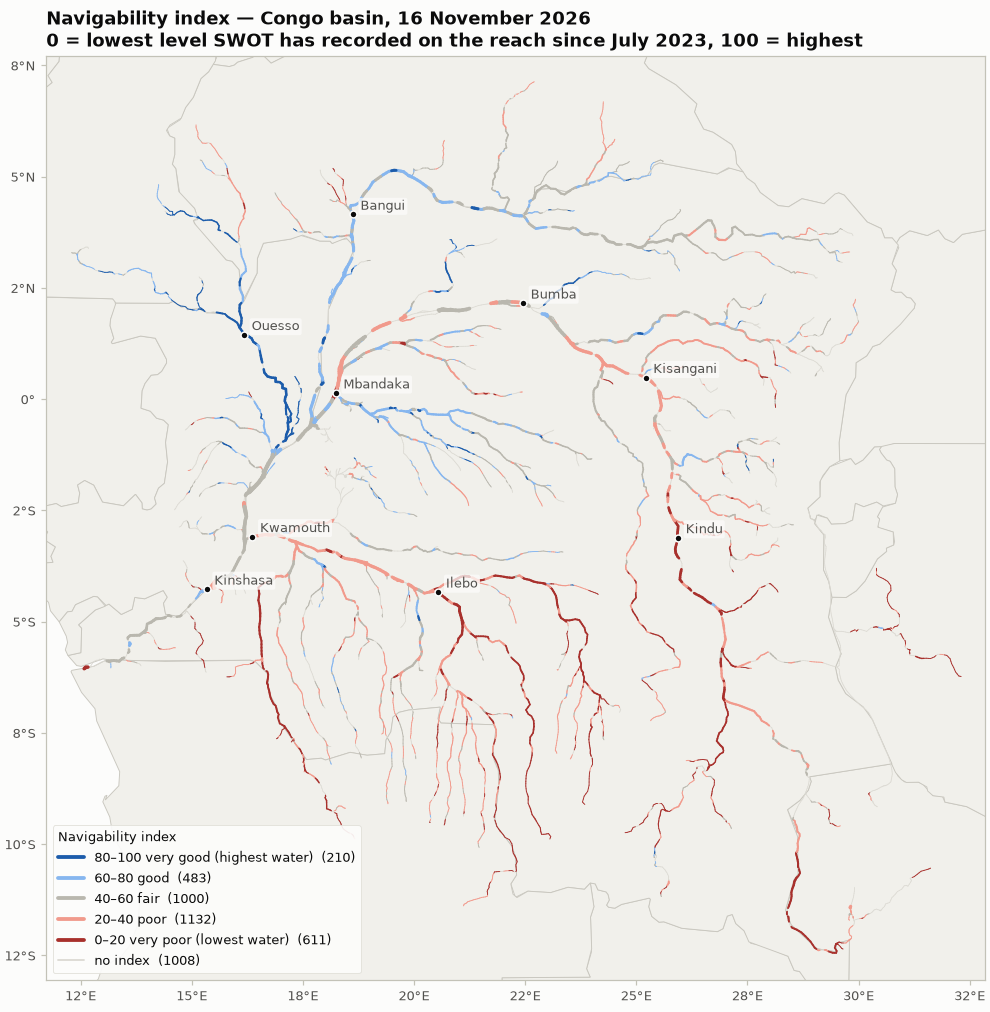

In [8]:
congo.navigability()

💬 **What do you notice?**

- Where is the water low today, and where is it high? Do rivers north and south of the equator differ?
- The Ubangi, the Sangha and the Uele drain the north of the basin; the Kasai and the Lualaba the south. Their rainy seasons come at different times of year. How does the map show that?
- How much of the river length is below 40? Would barges on the main river be loaded fully today?

### 4.1 Interactive map

Zoom in and click a river for its numbers: index, latest level and date, lowest and highest level, and the reach ID
(to use in `congo.reach(...)`). The black dots are river ports. The layer button (top right) changes the background.

In [9]:
congo.map()

## Part 5 — Along the river and at the ports



### 5.1 From Kindu to the sea

The Lualaba and the Congo, reach by reach from Kindu to the Atlantic. Top: the range of each reach (blue) and where its
latest level stands above the lowest. Bottom: the index.

,reach_id,river_name,dist_out_km,range_m,index
0,13279900061,Lwalaba,2649,4,9.3
1,13279900051,Lwalaba,2639,3.5,7.6
2,13279900041,Lwalaba,2629,3.9,9.5
3,13279900031,Lwalaba,2618,5.1,16.4
4,13279900021,Lwalaba,2608,4.6,7.7
5,13279900011,Lwalaba,2598,3.3,12.7
6,13279700111,Lwalaba,2587,3.8,23.3
7,13279700101,Lwalaba,2577,6.4,30.3
8,13279700091,Lwalaba,2566,4.6,15.4
9,13279700081,Lwalaba,2549,5.2,NaN

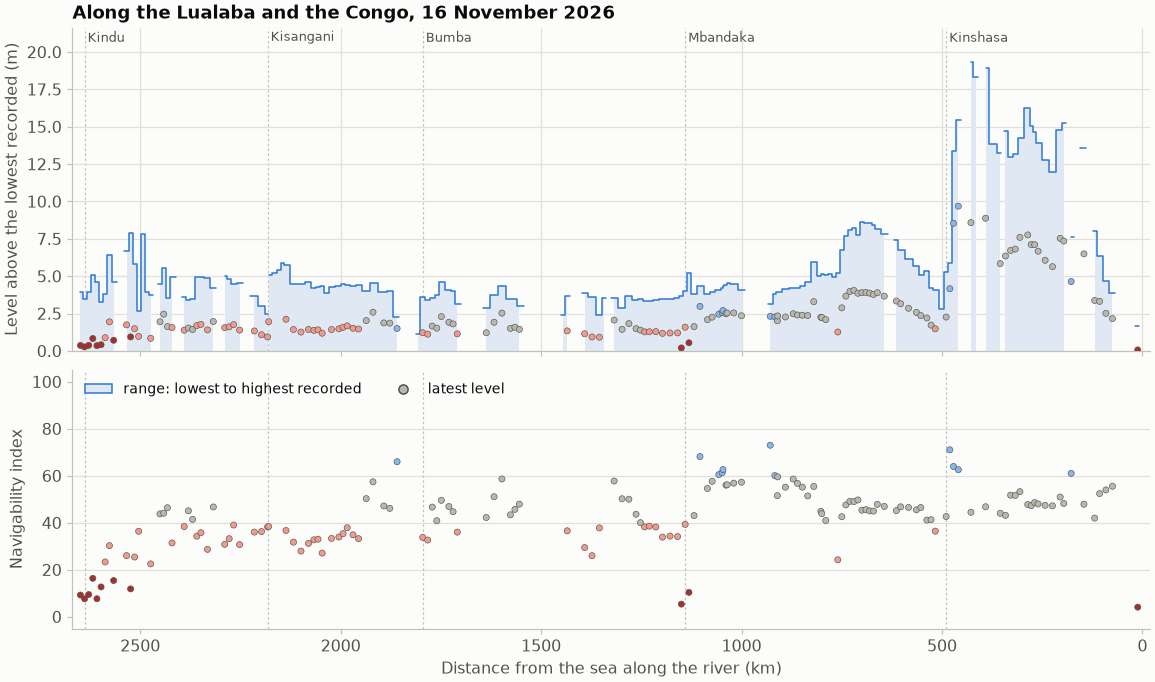

In [10]:
congo.profile()

💬 **What do you notice?**

- Where along the river is the range largest? (Hint: what lies between Kinshasa and the sea?)
- Is the index the same all along the river today? Where does it change, and which tributaries join there?

### 5.2 River ports

The index of every SWOT level since July 2023, at the reach nearest each port. The large dot is the latest level.

,port,river,reach,range (m),latest level,index,band
0,Kindu,Lualaba,13279900051,3.49,12 November 2026,8,0–20 very poor (lowest water)
1,Kisangani,Congo,13279300031,2.46,2 November 2026,38,20–40 poor
2,Bumba,Congo,13275700241,2.25,28 October 2026,54,40–60 fair
3,Mbandaka,Congo,13273000011,4.03,25 October 2026,39,20–40 poor
4,Bangui,Ubangi,13263100051,7.23,9 November 2026,63,60–80 good
5,Ouesso,Sangha,13245000311,4.65,10 November 2026,98,80–100 very good (highest water)
6,Ilebo,Kasai,13227000021,3.38,9 November 2026,23,20–40 poor
7,Kwamouth,Kasai,13221000021,8.53,5 November 2026,39,20–40 poor
8,Kinshasa,Congo,13217000081,5.31,21 October 2026,43,40–60 fair

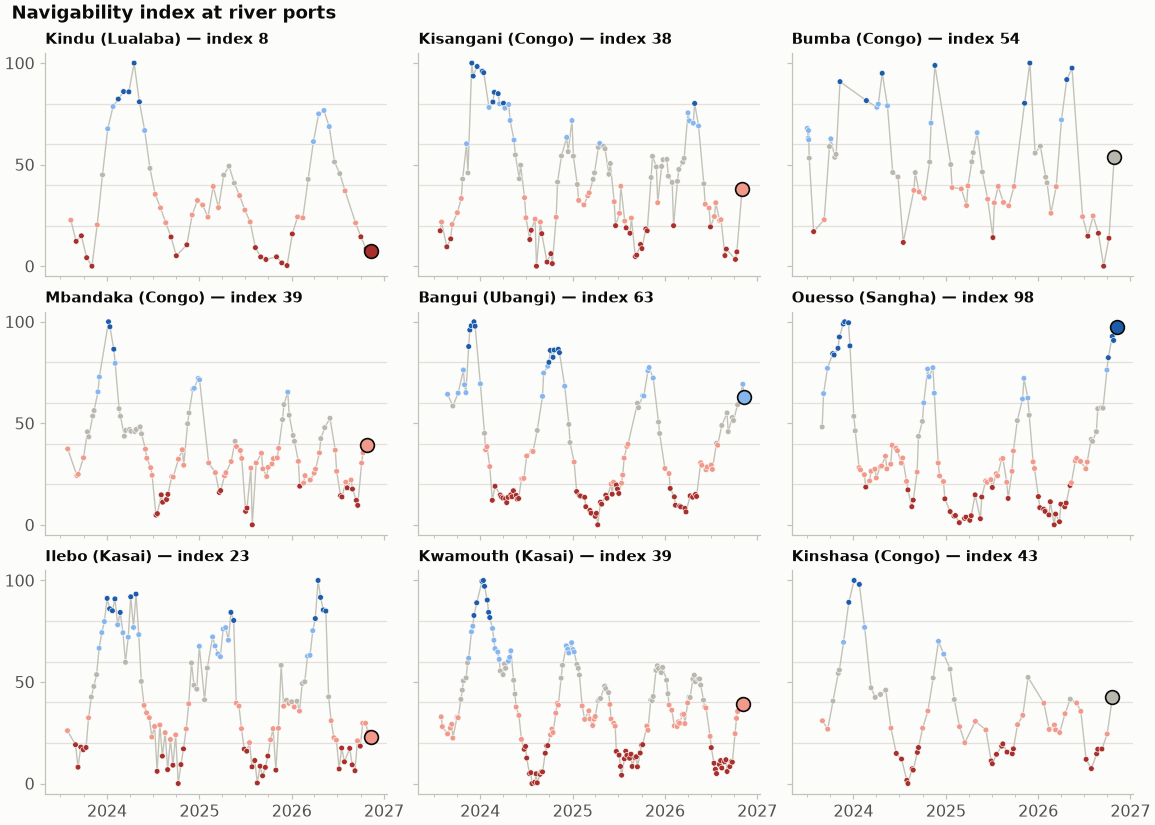

In [11]:
congo.ports()

💬 **What do you notice?**

- In which months is the water lowest at Bangui? At Ilebo? At Kinshasa?
- At Kinshasa, the Congo receives water from both hemispheres. How does that show in its record, compared with Bangui or Ilebo?
- A barge company plans a trip from Kinshasa to Bangui. Which months would you advise, and why?

## Part 6 — Through time

The same index on the first of every month: which share of the river length was at very poor, poor, fair, good or very
good water.

,reaches,0–20 very poor (lowest water),20–40 poor,40–60 fair,60–80 good,80–100 very good (highest water)
date,,,,,,
2026-01-01,3509,15,32,32,15,5
2026-02-01,3522,29,30,30,9,2
2026-03-01,3549,26,25,27,17,4
2026-04-01,3531,26,22,19,19,14
2026-05-01,3540,17,20,28,20,15
2026-06-01,3510,18,36,28,12,5
2026-07-01,3539,42,40,12,5,1
2026-08-01,3559,44,38,14,3,1
2026-09-01,3555,53,25,18,4,0

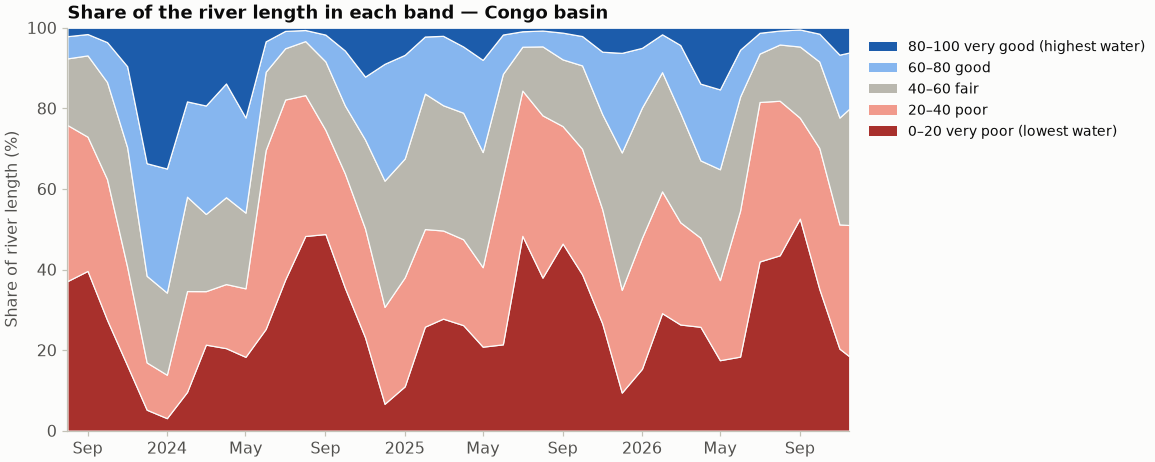

In [12]:
congo.history()

💬 **What do you notice?**

- When was the water lowest across the basin? Is today unusual?
- Why is the high water of December 2023 – January 2024 so dark blue, and never again as dark?

### 6.1 🧪 The map on another date

Any date since late 2023 — for instance the low water of mid-2025:

,band,reaches,river km,% of river km
0,0–20 very poor (lowest water),1338,17379,38
1,20–40 poor,1411,18423,40
2,40–60 fair,631,7831,17
3,60–80 good,146,1799,4
4,80–100 very good (highest water),23,317,1

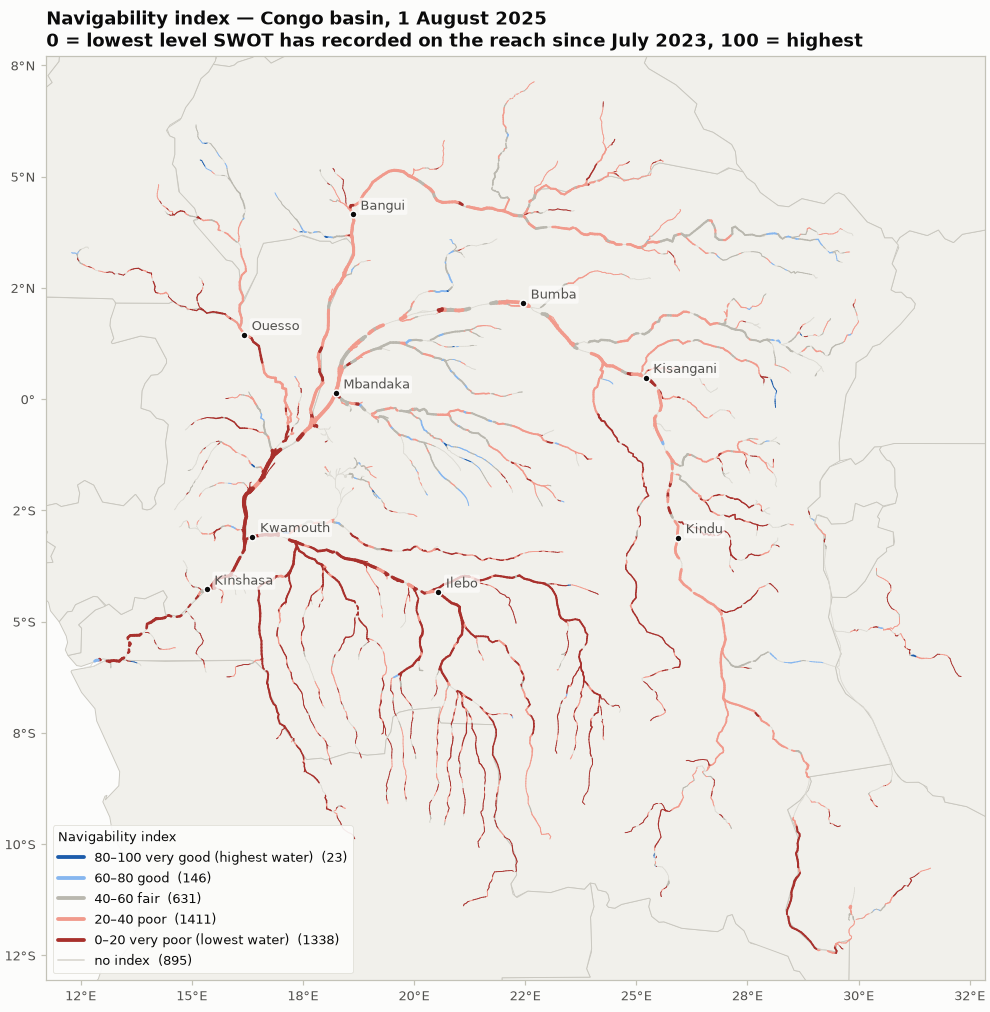

In [13]:
congo.navigability("2025-08-01")   # ✏️ a date, "YYYY-MM-DD"

## Part 7 — Change the settings

Every setting is a keyword of `congo.with_settings(...)` (or of `vg.river_survey`). The data are already on your
computer, so this is quick. Three tasks:

1. Allow an older ‘latest level’ (`max_age_days=60`). How many more reaches get an index? Is that a fair map of *today*?
2. Remove levels with a lot of **dark water** (`max_dark_frac=0.5`: more than half of the reach gave too little radar
   echo). What happens to the records at Bumba and at Ouesso?
3. Be stricter about noisy reaches (`max_noise_frac=0.1`). Which rivers lose their index?

,band,reaches,river km,% of river km
0,0–20 very poor (lowest water),673,8871,19
1,20–40 poor,1177,15034,32
2,40–60 fair,1034,13234,29
3,60–80 good,500,6418,14
4,80–100 very good (highest water),214,2783,6

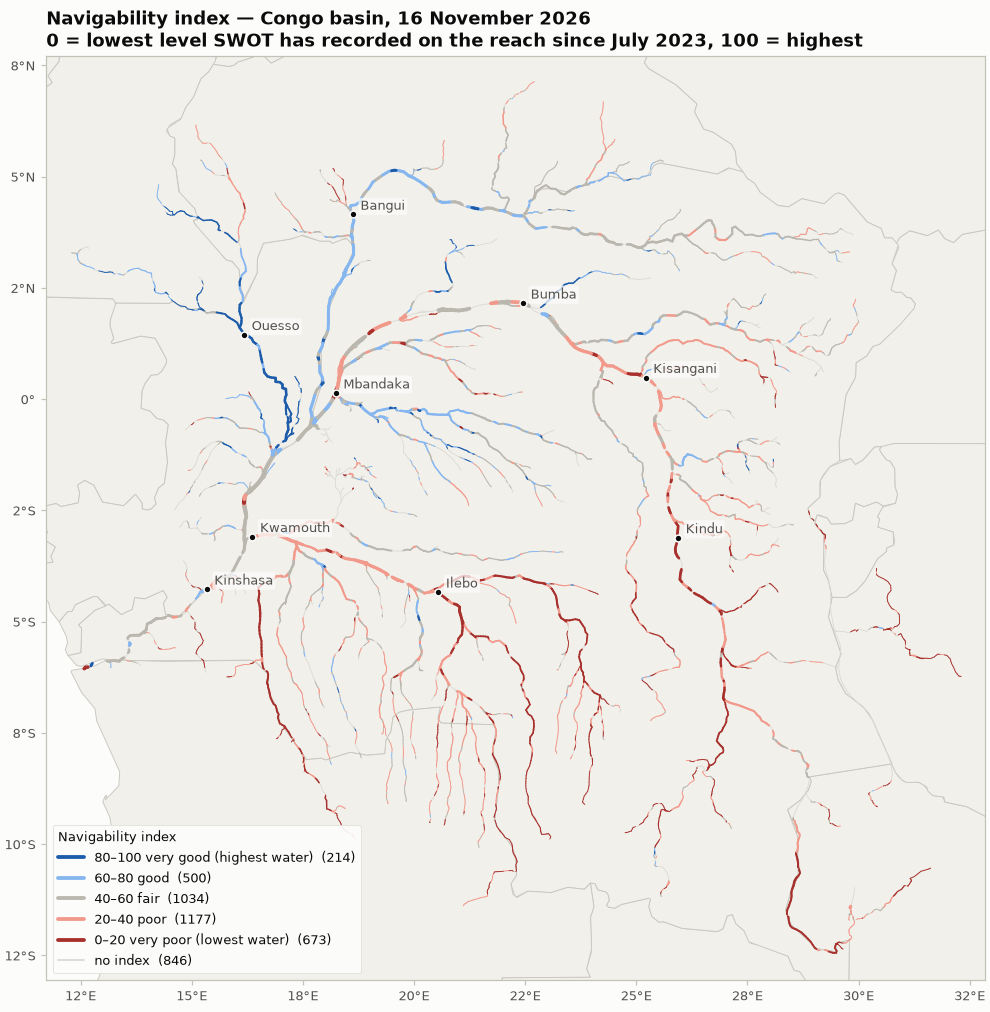

In [14]:
congo.with_settings(max_age_days=60).navigability()   # ✏️

,port,river,reach,range (m),latest level,index,band
0,Kindu,Lualaba,13279900051,3.4,12 November 2026,8,0–20 very poor (lowest water)
1,Kisangani,Congo,13279300031,2.43,2 November 2026,37,20–40 poor
2,Bumba,Congo,13275700241,3.11,28 October 2026,31,20–40 poor
3,Mbandaka,Congo,13273000011,3.74,25 October 2026,37,20–40 poor
4,Bangui,Ubangi,13263100051,6.78,9 November 2026,62,60–80 good
5,Ouesso,Sangha,13245000311,4.44,10 November 2026,100,80–100 very good (highest water)
6,Ilebo,Kasai,13227000021,3.25,29 September 2026,NaN,with no recent level
7,Kwamouth,Kasai,13221000021,8.18,5 November 2026,37,20–40 poor
8,Kinshasa,Congo,13217000081,5.31,21 October 2026,43,40–60 fair

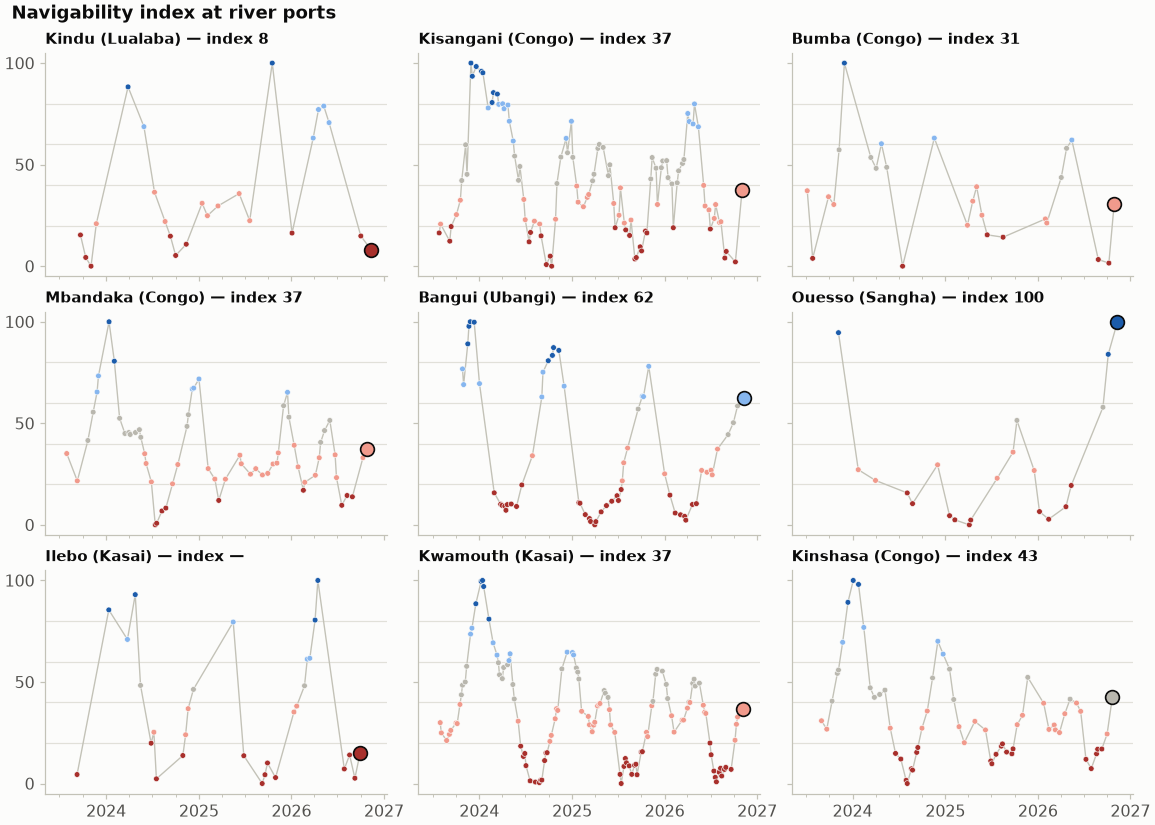

In [15]:
congo.with_settings(max_dark_frac=0.5).ports()   # ✏️

,band,reaches,river km,% of river km
0,0–20 very poor (lowest water),552,7439,20
1,20–40 poor,933,11727,32
2,40–60 fair,814,10378,28
3,60–80 good,399,5089,14
4,80–100 very good (highest water),191,2495,7

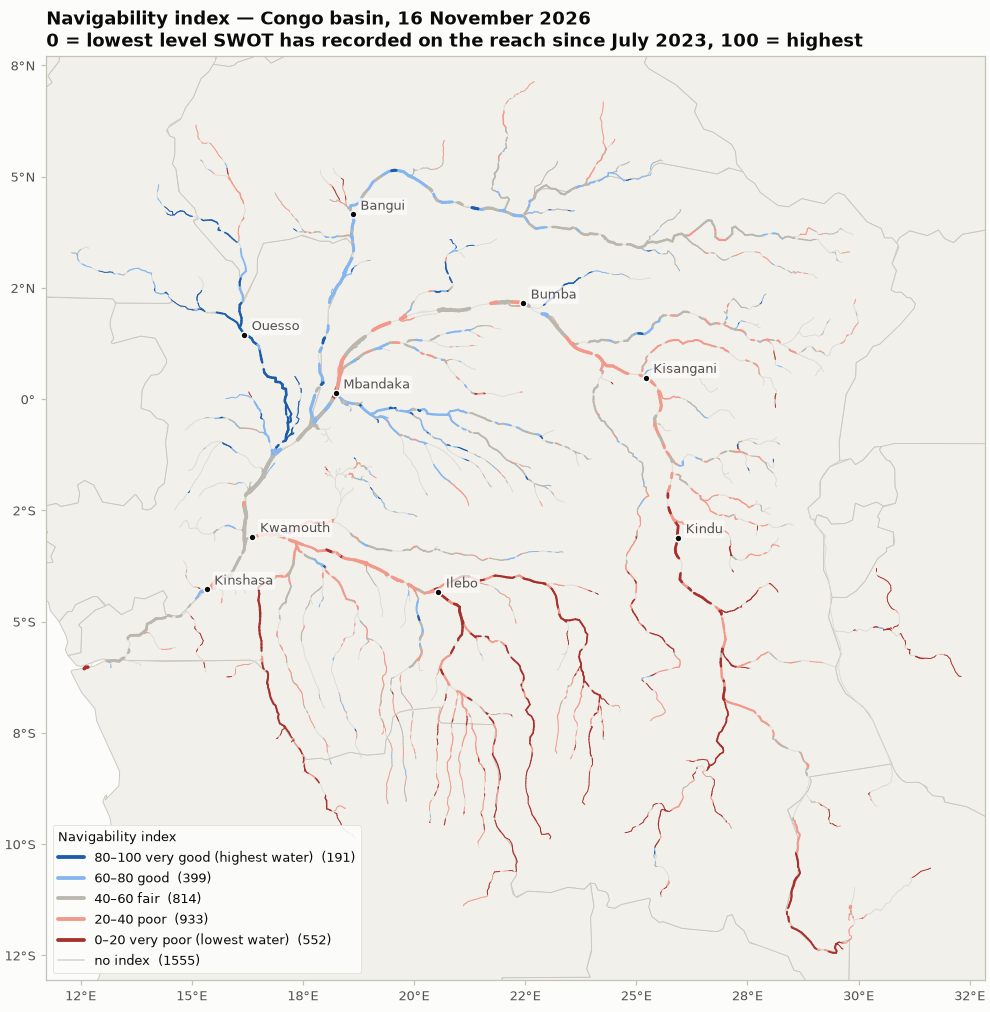

In [16]:
congo.with_settings(max_noise_frac=0.1).navigability()   # ✏️

All the settings, with their default values:

In [17]:
vg.SurveyParams()

SurveyParams(max_reach_q=1, max_xovr_q=1, max_dark_frac=1.0, k_mad=5.0, min_spread_m=0.25, jump_m=0.5, jump_k=4.0, jump_days=15, min_levels=10, min_span_days=365, min_range_m=0.5, max_noise_m=1.0, max_noise_frac=0.2, noise_days=6, max_age_days=30)

### 7.1 🧪 Your own list of reaches

Any list of SWOT reach IDs — here every reach within 60 km of Kinshasa and Brazzaville. Reaches already downloaded are
not downloaded again.

,band,reaches,river km,% of river km
0,0–20 very poor (lowest water),4,48,19
1,20–40 poor,8,101,39
2,40–60 fair,7,68,26
3,60–80 good,4,40,16
4,80–100 very good (highest water),0,0,0

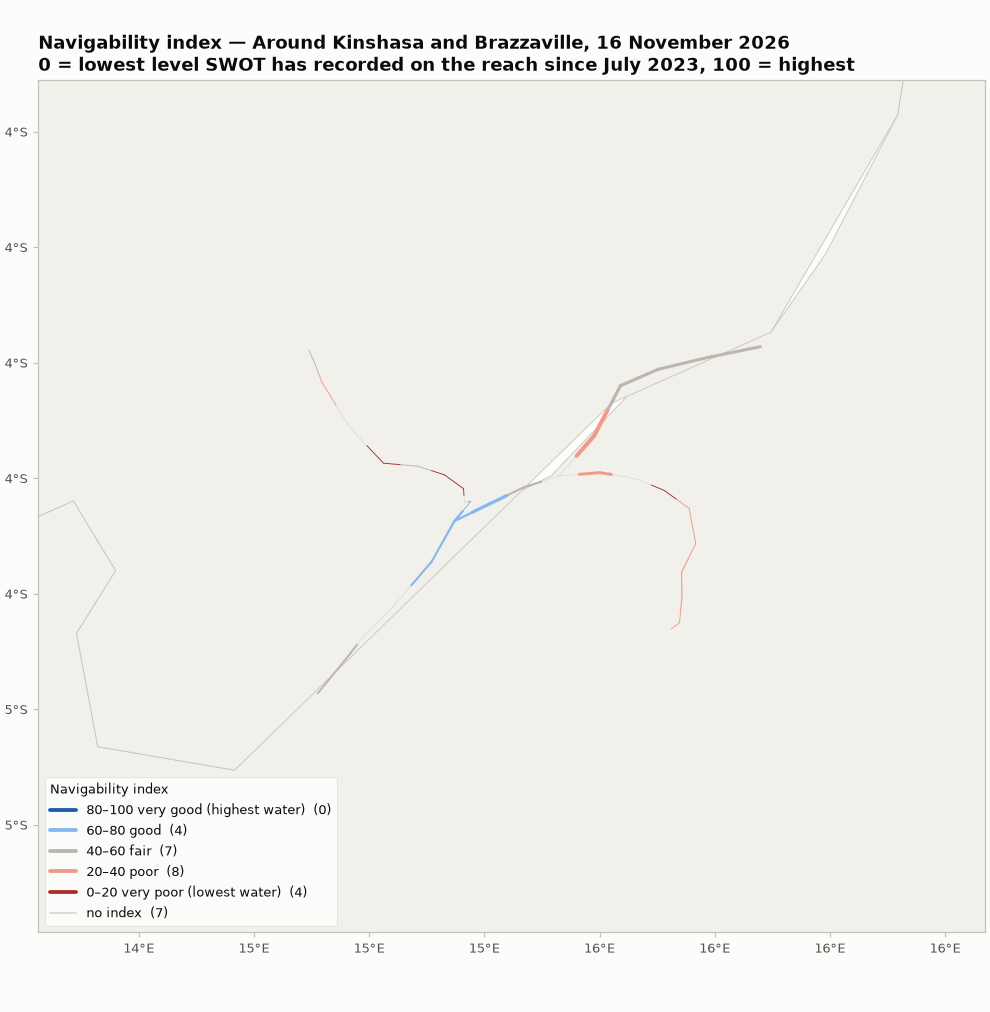

In [18]:
near = vg.reaches_near(-4.3, 15.3, radius_km=60, n=300).values["reach_ids"]   # ✏️ latitude, longitude
pool = vg.river_survey(reach_ids=near, name="Around Kinshasa and Brazzaville")
pool.navigability()

## Part 8 — Export and summary

Save the table of every reach (CSV: river, lowest and highest level, range, latest level, index) and the rivers with
their index (GeoJSON — open it in QGIS) in the folder `outputs/`.

In [19]:
congo.export()

Export
Written: outputs/navigability_congo_2026-11-16.csv
Written: outputs/navigability_congo_2026-11-16.geojson
Written: outputs/navigability_congo_2026-11-16_metadata.json

The ten reaches with the lowest water today, as a table you can sort and filter (pandas):

In [20]:
table = congo.to_dataframe()
table[table.width_m > 300].sort_values("index")[["reach_id", "river_name", "width_m", "range_m", "now_date", "index"]].head(10)

,reach_id,river_name,width_m,range_m,now_date,index
950,13226500051,Sankuru,342.0,3.861,2026-10-28 22:19:16,0.000000
951,13226500061,Sankuru,342.0,3.968,2026-10-28 22:19:17,1.638105
955,13226500101,Sankuru,366.0,3.821,2026-10-28 22:19:23,3.637791
949,13226500041,Sankuru,366.0,3.771,2026-10-28 22:19:14,3.792098
0,13211000025,Congo,3392.0,1.661,2026-10-27 11:06:57,4.093919
150,13222500021,Fimi,508.0,3.743,2026-11-10 20:42:39,4.702111
2803,13273000021,Congo,3646.0,3.699,2026-10-30 22:18:57,5.379832
4351,13297100351,Luapula River,318.0,2.885,2026-11-06 20:43:01,6.447140
4352,13297100361,Luapula River,302.0,2.632,2026-11-06 20:43:02,6.914894
948,13226500031,Sankuru,350.0,3.995,2026-10-28 22:19:13,7.008761


## Summary

- SWOT measures the **water level** of every river reach in the basin, not its depth. Comparing each reach with its
  own lowest and highest level turns those heights into a simple **navigability index**.
- The index is only as good as the **record**: three years, with an exceptional flood at the start, and the lowest and
  highest values are each a single measurement — so cleaning the levels first matters.
- **Narrow rivers**, very wide braided ones and **dark water** give noisy records; those reaches get no index.
- ‘Today’ means the **last few weeks**: SWOT passes each reach a few times every 21 days.
- What the index cannot tell: the real depth over sand bars, the draught of the boats, rapids and falls, or whether
  high water is too fast or too high under bridges. Local knowledge and gauge readings complete it.

For water levels and discharge at one place, see `Virtual_River_Gauges_Student.ipynb`; for flood maps,
`SWOT_Flood_Depth_Student.ipynb`.

In [21]:
vg.credits()

Data: ICESat-2 ATL13 v007 (NASA/NSIDC, doi:10.5067/ATLAS/ATL13.007) via SlideRule Earth; SWOT RiverSP Version D (NASA/CNES, PO.DAAC) via Hydrocron; GEOGloWS v2 (ECMWF); SWORD v17b river database (Altenau et al. 2021, CC BY 4.0); Botswana border and the country borders of the Congo maps: Natural Earth (public domain). Optional: GRDC, DAHITI (CC BY 4.0). Flood maps: SWOT L2 HR Raster 100 m Version D (NASA/CNES, PO.DAAC, doi:10.5067/SWOT-RASTER-D); Copernicus DEM GLO-30 (© DLR e.V. 2010–2014 and © Airbus Defence and Space GmbH 2014–2018, provided under COPERNICUS by the European Union and ESA).